# Chuong 2. Dữ liệu công trình và tiền xử lý
Mã lệnh của các ví dụ trong giáo trình Khoa học dữ liệu công trình, chạy tuần tự từ trên xuống.

[Mở trên Google Colab](https://colab.research.google.com/github/ngochoautc/khoa-hoc-du-lieu-cong-trinh/blob/main/notebooks/Chuong2.ipynb)

## CÁC NGUỒN DỮ LIỆU CÔNG TRÌNH

### Nguồn dữ liệu và đặc điểm

### Quy trình phân tích dữ liệu công trình

### Đọc dữ liệu vào Python

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats

# Noi dung tep CSV xuat tu bang tinh tieng Viet
van_ban = """thoi_gian;bien_dang;nhiet_do
01/03/2026 08:00;152,3;24,1
01/03/2026 08:01;152,9;24,1
01/03/2026 08:02;;24,2
01/03/2026 08:03;153,4;24,2
01/03/2026 08:04;153,1;24,3
"""
sai = pd.read_csv(io.StringIO(van_ban))
print("Doc mac dinh, kich thuoc:", sai.shape)

df_csv = pd.read_csv(io.StringIO(van_ban), sep=";",
                     decimal=",",
                     parse_dates=["thoi_gian"],
                     date_format="%d/%m/%Y %H:%M",
                     index_col="thoi_gian")
print(df_csv.dtypes)
print(df_csv)

Doc mac dinh, kich thuoc: (5, 1)
bien_dang    float64
nhiet_do     float64
dtype: object
                     bien_dang  nhiet_do
thoi_gian                               
2026-03-01 08:00:00      152.3      24.1
2026-03-01 08:01:00      152.9      24.1
2026-03-01 08:02:00        NaN      24.2
2026-03-01 08:03:00      153.4      24.2
2026-03-01 08:04:00      153.1      24.3


*Mẫu đọc tệp Excel quan trắc; cần tệp quan_trac_T3.xlsx của người dùng.*

```
# Doc trang tinh "Nhip2" cua tep quan trac thang 3
df_x = pd.read_excel("quan_trac_T3.xlsx",
                     sheet_name="Nhip2", skiprows=2,
                     parse_dates=["thoi_gian"],
                     index_col="thoi_gian")
df_x.info()      # kiem tra kieu du lieu tung cot
```

In [2]:
# Chuoi bien dang ghi moi phut trong 1 gio (mo phong)
rng = np.random.default_rng(213)
tg = pd.date_range("2026-03-01 08:00", periods=60,
                   freq="min")
bd = 152 + 0.05 * np.arange(60) + rng.normal(0, 0.4, 60)
ct = pd.Series(bd, index=tg, name="bien_dang")
g10 = ct.resample("10min").agg(["mean", "max", "count"])
print(g10.round(2))

                       mean     max  count
2026-03-01 08:00:00  152.22  153.06     10
2026-03-01 08:10:00  152.54  153.02     10
2026-03-01 08:20:00  153.46  154.15     10
2026-03-01 08:30:00  153.66  154.21     10
2026-03-01 08:40:00  154.39  155.07     10
2026-03-01 08:50:00  154.67  155.11     10


## LÀM SẠCH, CHUẨN HÓA VÀ XỬ LÝ DỮ LIỆU THIẾU

### Phát hiện và xử lý dữ liệu thiếu

In [3]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats

# Quan trac do vong dam (mm), nhiet do (do C), moi gio
df = pd.DataFrame({
    "thoi_diem": pd.date_range("2026-01-01", periods=12,
                               freq="h"),
    "do_vong": [12.1, 12.4, np.nan, 12.8, 13.0, np.nan,
                np.nan, 13.5, 13.2, 12.9, 12.6, 12.3],
    "nhiet_do": [22.1, 23.4, 24.8, 26.2, 27.5, 28.1,
                 28.4, 27.9, 26.3, 24.7, 23.2, 22.4]})
df = df.set_index("thoi_diem")
print("So gia tri thieu tung cot:")
print(df.isna().sum().to_string())
ty_le = df["do_vong"].isna().mean()
print(f"Ty le thieu cot do_vong: {ty_le:.1%}")
# Kieu nullable Int64: gia tri thieu la pd.NA
sl = pd.Series([3, None, 5], dtype="Int64")
print(sl.dtype, sl.tolist())

So gia tri thieu tung cot:
do_vong     3
nhiet_do    0
Ty le thieu cot do_vong: 25.0%
Int64 [3, <NA>, 5]


In [4]:
# Noi suy theo truc thoi gian; dien gia tri lien truoc
df["do_vong_noi_suy"] = df["do_vong"].interpolate(
    method="time")
df["do_vong_ffill"] = df["do_vong"].ffill()
bang = df[["do_vong", "do_vong_noi_suy", "do_vong_ffill"]]
print(bang.set_axis(df.index.strftime("%H:%M")).round(2))

           do_vong  do_vong_noi_suy  do_vong_ffill
thoi_diem                                         
00:00         12.1            12.10           12.1
01:00         12.4            12.40           12.4
02:00          NaN            12.60           12.4
03:00         12.8            12.80           12.8
04:00         13.0            13.00           13.0
05:00          NaN            13.17           13.0
06:00          NaN            13.33           13.0
07:00         13.5            13.50           13.5
08:00         13.2            13.20           13.2
09:00         12.9            12.90           12.9
10:00         12.6            12.60           12.6
11:00         12.3            12.30           12.3


### Thống nhất kiểu dữ liệu, đơn vị và kiểm tra tính nhất quán

In [5]:
# Ket qua nen mau tu hai phong thi nghiem (gia dinh)
kq = pd.DataFrame({
    "ma_ck": ["T1", "T2", "T2", "T3", "T5", "T7"],
    "cuong_do": ["38,5", "41.2 MPa", "41.2 MPa", "395 kG/cm2",
                 "37,4", "0"]})
try:
    pd.to_numeric(kq["cuong_do"])
except ValueError as loi:
    print("Loi:", loi)
chuoi = kq["cuong_do"].str.strip()
la_kg = chuoi.str.contains("kG/cm2", regex=False)
chuoi = (chuoi.str.replace("kG/cm2", "", regex=False)
              .str.replace("MPa", "", regex=False)
              .str.replace(",", ".", regex=False).str.strip())
kq["cuong_do_MPa"] = pd.to_numeric(chuoi, errors="coerce")
kq.loc[la_kg, "cuong_do_MPa"] *= 0.0981   # kG/cm2 -> MPa
kq = kq.drop(columns="cuong_do").drop_duplicates()
danh_muc = ["T1", "T2", "T3", "T4", "T5"]
kq["sai_ma"] = ~kq["ma_ck"].isin(danh_muc)
kq["ngoai_mien"] = ~kq["cuong_do_MPa"].between(1, 120)
print(kq.round(2).to_string(index=False))
print("Truc thoi gian tang dan:",
      df.index.is_monotonic_increasing,
      "| so moc trung:", df.index.duplicated().sum())

Loi: Unable to parse string "38,5" at position 0
ma_ck  cuong_do_MPa  sai_ma  ngoai_mien
   T1         38.50   False       False
   T2         41.20   False       False
   T3         38.75   False       False
   T5         37.40   False       False
   T7          0.00    True        True
Truc thoi gian tang dan: True | so moc trung: 0


### Chuẩn hóa thang đo của các biến

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

# 40 nhip dam gia dinh: nhip (m), tai (kN), tan so (Hz)
rng = np.random.default_rng(223)
nhip = rng.uniform(18, 42, 40)
X = pd.DataFrame({
    "nhip_m": nhip.round(1),
    "tai_kN": rng.uniform(600, 2400, 40).round(0),
    "tan_so_Hz": (100 / nhip
                  + rng.normal(0, 0.2, 40)).round(2)})
print(X.agg(["min", "max"]).round(2))
X_tr, X_te = train_test_split(X, test_size=0.25,
                              random_state=1)
sc = StandardScaler().fit(X_tr)   # chi fit tren tap HL
Z_tr, Z_te = sc.transform(X_tr), sc.transform(X_te)
print("x_tb (tap HL):", sc.mean_.round(2))
print("s    (tap HL):", sc.scale_.round(2))
print("TB  Z_tr:", Z_tr.mean(axis=0).round(2) + 0.0)
print("TB  Z_te:", Z_te.mean(axis=0).round(2) + 0.0)
print("DLC Z_te:", Z_te.std(axis=0).round(2))
mm = MinMaxScaler().fit(X_tr)
U_te = mm.transform(X_te)
print("U_te nho nhat:", U_te.min(axis=0).round(3))
print("U_te lon nhat:", U_te.max(axis=0).round(3))

     nhip_m  tai_kN  tan_so_Hz
min    18.4   632.0       2.23
max    41.5  2396.0       5.53
x_tb (tap HL): [  30.66 1455.23    3.46]
s    (tap HL): [  7.67 580.08   1.03]
TB  Z_tr: [0. 0. 0.]
TB  Z_te: [-0.47  0.03  0.38]
DLC Z_te: [0.77 0.77 0.91]
U_te nho nhat: [ 0.035  0.087 -0.022]
U_te lon nhat: [0.883 0.954 0.944]


## PHÁT HIỆN DỮ LIỆU BẤT THƯỜNG

### Phát hiện giá trị ngoại lai

In [7]:
# Cuong do 20 mau be tong (MPa), co gia tri nghi ngo
cd = pd.Series([38.2, 39.1, 37.5, 38.8, 39.5, 37.9, 38.4, 39.0,
                12.5, 38.6, 37.2, 38.9, 39.3, 38.1, 37.8, 38.5,
                52.8, 38.3, 39.2, 38.7])
Q1, Q3 = cd.quantile(0.25), cd.quantile(0.75)
IQR = Q3 - Q1
can_duoi, can_tren = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
ngoai_lai = cd[(cd < can_duoi) | (cd > can_tren)]
print(f"Q1 = {Q1:.3f}, Q3 = {Q3:.3f} MPa")
print(f"Khoang chap nhan: [{can_duoi:.2f}; {can_tren:.2f}] MPa")
print("Ngoai lai theo IQR       :", ngoai_lai.tolist())
z = (cd - cd.mean()) / cd.std()
print("Ngoai lai theo |z| > 3   :", cd[z.abs() > 3].tolist())
print(f"z(12.5) = {z[8]:.2f}, z(52.8) = {z[16]:.2f}")
med = cd.median()
mad = (cd - med).abs().median()
z_ben = (cd - med) / (1.4826 * mad)
print(f"Trung vi = {med:.2f} MPa, MAD = {mad:.2f} MPa")
print("Ngoai lai theo |zR| > 3.5:",
      cd[z_ben.abs() > 3.5].tolist())
print(f"zR(12.5) = {z_ben[8]:.1f}, zR(52.8) = {z_ben[16]:.1f}")

Q1 = 38.050, Q3 = 39.025 MPa
Khoang chap nhan: [36.59; 40.49] MPa
Ngoai lai theo IQR       : [12.5, 52.8]
Ngoai lai theo |z| > 3   : [12.5]
z(12.5) = -3.73, z(52.8) = 2.19
Trung vi = 38.55 MPa, MAD = 0.50 MPa
Ngoai lai theo |zR| > 3.5: [12.5, 52.8]
zR(12.5) = -35.1, zR(52.8) = 19.2


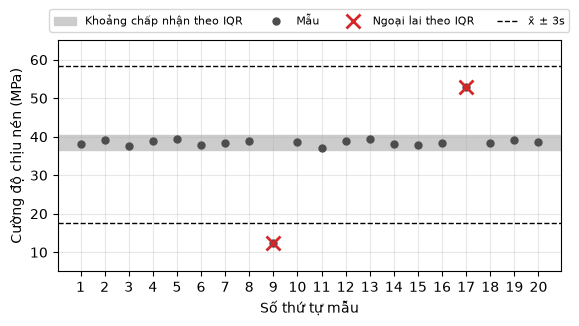

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.0))
stt = np.arange(1, cd.size + 1)
ax.axhspan(can_duoi, can_tren, color="0.8",
           label="Khoảng chấp nhận theo IQR")
ax.plot(stt, cd, "o", color="0.3", ms=5, label="Mẫu")
ax.plot(ngoai_lai.index + 1, ngoai_lai, "x", color="C3",
        ms=10, mew=2, label="Ngoại lai theo IQR")
for k in (-3, 3):
    ax.axhline(cd.mean() + k * cd.std(), color="k", ls="--",
               lw=1, label="x̄ ± 3s" if k > 0 else None)
ax.set_xticks(stt)
ax.set_xlabel("Số thứ tự mẫu")
ax.set_ylabel("Cường độ chịu nén (MPa)")
ax.set_ylim(5, 65)
ax.grid(alpha=0.3)
ax.legend(loc="upper center", ncol=4, fontsize=8,
          bbox_to_anchor=(0.5, 1.16))
plt.show()

In [9]:
con_lai = cd.drop(ngoai_lai.index)
for ten, x in (("Giu ngoai lai ", cd),
               ("Loai ngoai lai", con_lai)):
    tb, s_x = x.mean(), x.std()
    print(f"{ten}: n = {x.size}, TB = {tb:.2f}, s = {s_x:.2f},"
          f" TB - 1.64s = {tb - 1.64 * s_x:.2f} MPa")

Giu ngoai lai : n = 20, TB = 37.91, s = 6.81, TB - 1.64s = 26.75 MPa
Loai ngoai lai: n = 18, TB = 38.50, s = 0.64, TB - 1.64s = 37.46 MPa


### Bất thường trong chuỗi số liệu quan trắc

1.4826*MAD = 0.55 microstrain
k = 3.5: phat hien 29, dung 8, bao sai 21, bo sot 0
k = 5.0: phat hien 9, dung 8, bao sai 1, bo sot 0
Bao sai (k = 5) tai: 2026-04-06 16:50:00
Doan phang: 36 mau, tu 2026-04-05 04:00:00 den 2026-04-05 09:50:00


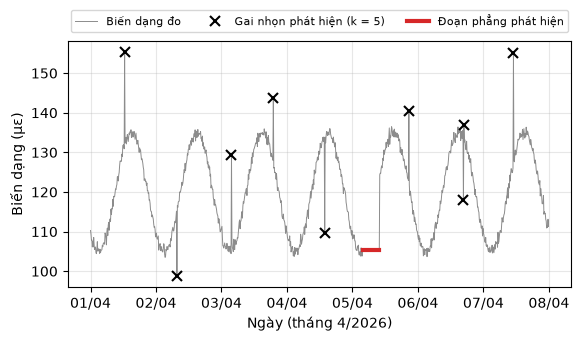

In [10]:
# Bien dang 7 ngay, lay mau 10 phut (so lieu mo phong)
rng = np.random.default_rng(232)
tg = pd.date_range("2026-04-01", periods=7 * 144,
                   freq="10min")
gio = np.arange(tg.size) / 6.0
nhiet = 26 + 6 * np.sin(2 * np.pi * (gio - 9) / 24)
bd = 120 + 2.5 * (nhiet - 26)
s = pd.Series(bd + rng.normal(0, 0.8, tg.size),
              index=tg)              # microstrain
# Chen 8 gai nhon va 1 doan phang 6 gio
vt_gai = np.array([75, 190, 310, 402, 515, 700, 820, 930])
s.iloc[vt_gai] += [22, -18, 25, 16, -24, 20, -15, 28]
s.iloc[600:636] = s.iloc[600]

# Trung vi truot 13 mau (2 gio) va MAD cua phan du
m = s.rolling(13, center=True, min_periods=1).median()
r = s - m
mad = np.median(np.abs(r - np.median(r)))
z = r.abs() / (1.4826 * mad)
print("1.4826*MAD =", round(1.4826 * mad, 2), "microstrain")
for k in (3.5, 5.0):
    pt = np.flatnonzero(z > k)
    dung = np.intersect1d(pt, vt_gai).size
    print(f"k = {k}: phat hien {pt.size}, dung {dung},"
          f" bao sai {pt.size - dung}, bo sot {8 - dung}")
gai = z > 5.0
sai_k5 = np.setdiff1d(np.flatnonzero(gai), vt_gai)
print("Bao sai (k = 5) tai:", s.index[sai_k5][0])
# Doan phang: tu 6 mau lien tiep bang nhau tro len
nhom = (s.diff() != 0).cumsum()
phang = s.groupby(nhom).transform("size") >= 6
print("Doan phang:", phang.sum(), "mau, tu",
      s.index[phang][0], "den", s.index[phang][-1])

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(s.index, s, color="0.55", lw=0.7,
        label="Biến dạng đo")
ax.plot(s.index[gai], s[gai], "kx", ms=7, mew=1.5,
        label="Gai nhọn phát hiện (k = 5)")
ax.plot(s.index[phang], s[phang], color="C3", lw=3,
        label="Đoạn phẳng phát hiện")
ax.set_xlabel("Ngày (tháng 4/2026)")
ax.set_ylabel("Biến dạng (µε)")
ax.xaxis.set_major_formatter(
    plt.matplotlib.dates.DateFormatter("%d/%m"))
ax.grid(alpha=0.3)
ax.legend(loc="upper center", ncol=3, fontsize=8,
          bbox_to_anchor=(0.5, 1.15))
plt.show()

## TRÍCH XUẤT ĐẶC TRƯNG TỪ TÍN HIỆU ĐO

### Tín hiệu số và tần số lấy mẫu

fs = 100.0 Hz: fN = 50.0 Hz, tan so ghi nhan = 12.5 Hz
fs =  15.0 Hz: fN =  7.5 Hz, tan so ghi nhan = 2.5 Hz


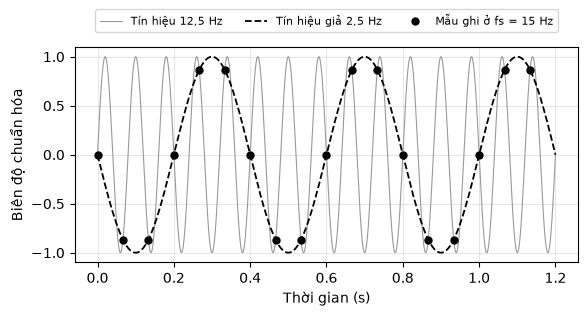

In [11]:
# Song 12,5 Hz lay mau o 100 Hz va o 15 Hz
f0 = 12.5
for fs_thu in (100.0, 15.0):
    fa = abs(f0 - round(f0 / fs_thu) * fs_thu)
    print(f"fs = {fs_thu:5.1f} Hz: fN = {fs_thu / 2:4.1f} Hz,"
          f" tan so ghi nhan = {fa:.1f} Hz")

t_lt = np.linspace(0, 1.2, 3001)   # gan lien tuc
t15 = np.arange(0, 1.2, 1 / 15)
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(t_lt, np.sin(2 * np.pi * f0 * t_lt),
        color="0.6", lw=0.8, label="Tín hiệu 12,5 Hz")
ax.plot(t_lt, np.sin(2 * np.pi * (f0 - 15) * t_lt),
        "k--", lw=1.3, label="Tín hiệu giả 2,5 Hz")
ax.plot(t15, np.sin(2 * np.pi * f0 * t15), "ko", ms=5,
        label="Mẫu ghi ở fs = 15 Hz")
ax.set_xlabel("Thời gian (s)")
ax.set_ylabel("Biên độ chuẩn hóa")
ax.grid(alpha=0.3)
ax.legend(loc="upper center", ncol=3, fontsize=8,
          bbox_to_anchor=(0.5, 1.2))
plt.show()

### Đặc trưng miền thời gian

In [12]:
# Gia toc giua nhip dam ~33 m, fs = 100 Hz, 60 s (mo phong)
fs = 100.0
t = np.arange(0, 60, 1 / fs)
rng = np.random.default_rng(242)
a1 = (0.020 * np.sin(2 * np.pi * 3.2 * t)
      + 0.008 * np.sin(2 * np.pi * 7.9 * t + 0.6)
      + 0.006 * np.sin(2 * np.pi * 12.5 * t + 1.1)
      + rng.normal(0, 0.008, t.size))         # m/s2
# Xe nang qua tu giay 20: dao dong tat dan 3,2 Hz
xe = np.exp(-0.6 * np.clip(t - 20, 0, None)) * (t >= 20)
a2 = a1 + 0.08 * xe * np.sin(2 * np.pi * 3.2 * (t - 20))

def dac_trung(x):
    rms = np.sqrt(np.mean(x ** 2))
    dinh = np.max(np.abs(x))
    return {"dinh": dinh, "trung_binh": x.mean(),
            "do_lech_chuan": x.std(), "rms": rms,
            "he_so_dinh": dinh / rms,
            "do_nhon": stats.kurtosis(x, fisher=False)}

bang_tg = pd.DataFrame({"a1": dac_trung(a1),
                        "a2": dac_trung(a2)})
print(bang_tg.round(4))

                   a1      a2
dinh           0.0534  0.1046
trung_binh    -0.0002 -0.0001
do_lech_chuan  0.0175  0.0198
rms            0.0175  0.0198
he_so_dinh     3.0480  5.2728
do_nhon        2.3877  3.9338


### Đặc trưng miền tần số

FFT: delta f = 0.0167 Hz
  dinh  3.200 Hz, bien do 0.0196 m/s2
  dinh  7.900 Hz, bien do 0.0079 m/s2
  dinh 12.500 Hz, bien do 0.0059 m/s2
Welch: delta f = 0.0488 Hz
  dinh: [ 3.223  7.91  12.5  ] Hz


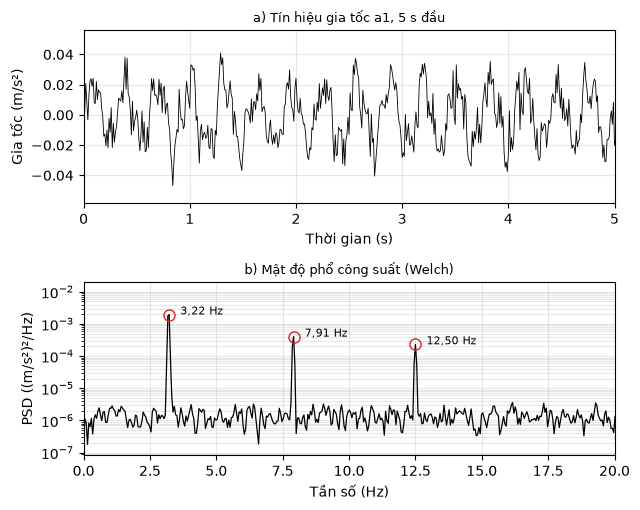

In [13]:
# Pho bien do bang FFT tren toan bo 60 s cua a1
N = a1.size
A = 2 * np.abs(np.fft.rfft(a1)) / N
f = np.fft.rfftfreq(N, d=1 / fs)
pk, _ = signal.find_peaks(A, height=0.004)
print("FFT: delta f =", round(fs / N, 4), "Hz")
for i in pk:
    print(f"  dinh {f[i]:6.3f} Hz, bien do {A[i]:.4f} m/s2")
# Mat do pho cong suat theo Welch, doan 2048 mau
fw, P = signal.welch(a1, fs=fs, nperseg=2048)
pw, _ = signal.find_peaks(P, height=0.02 * P.max(),
                          distance=10)
print("Welch: delta f =", round(fw[1], 4), "Hz")
print("  dinh:", fw[pw].round(3), "Hz")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.5, 5.2))
ax1.plot(t, a1, color="k", lw=0.6)
ax1.set_xlim(0, 5)
ax1.set_xlabel("Thời gian (s)")
ax1.set_ylabel("Gia tốc (m/s²)")
ax1.set_title("a) Tín hiệu gia tốc a1, 5 s đầu", fontsize=9)
ax1.grid(alpha=0.3)
ax2.semilogy(fw, P, color="k", lw=0.9)
ax2.plot(fw[pw], P[pw], "o", mfc="none", mec="C3", ms=8)
for i in pw:
    nhan = f"{fw[i]:.2f} Hz".replace(".", ",")
    ax2.annotate(nhan, (fw[i], P[i]), xytext=(8, 0),
                 textcoords="offset points", fontsize=8)
ax2.set_xlim(0, 20)
ax2.set_ylim(top=10 * P.max())
ax2.set_xlabel("Tần số (Hz)")
ax2.set_ylabel("PSD ((m/s²)²/Hz)")
ax2.set_title("b) Mật độ phổ công suất (Welch)", fontsize=9)
ax2.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

### Lập bảng đặc trưng cho mô hình

In [14]:
# 48 doan 60 s, moi doan cach nhau 30 phut (mo phong)
rng = np.random.default_rng(244)
gio = np.arange(48) * 0.5
T_kc = (24 + 8 * np.sin(2 * np.pi * (gio - 9) / 24)
        + rng.normal(0, 0.5, 48))           # do C
f1_mp = (3.20 * (1 - 0.002 * (T_kc - 20))
         + rng.normal(0, 0.004, 48))        # Hz
hang = []
for j in range(48):
    bien_do = 0.010 + 0.015 * rng.random()
    x = (bien_do * np.sin(2 * np.pi * f1_mp[j] * t
                          + rng.uniform(0, 2 * np.pi))
         + 0.006 * np.sin(2 * np.pi * 12.5 * t)
         + rng.normal(0, 0.008, t.size))
    # Them so 0 (n = 4N) de luoi tan so min hon
    nn = 4 * t.size
    Ax = np.abs(np.fft.rfft(x, n=nn))
    fx = np.fft.rfftfreq(nn, d=1 / fs)
    vung = (fx > 2) & (fx < 5)     # vung uon thu nhat
    hang.append({"gio": gio[j], "nhiet_do": T_kc[j],
                 "rms": np.sqrt(np.mean(x ** 2)),
                 "dinh": np.max(np.abs(x)),
                 "f1": fx[vung][np.argmax(Ax[vung])]})
bang_dt = pd.DataFrame(hang)
print(bang_dt.head(4).round(4))
print("Kich thuoc bang:", bang_dt.shape)
he_so = np.polyfit(bang_dt["nhiet_do"], bang_dt["f1"], 1)
r = np.corrcoef(bang_dt["nhiet_do"], bang_dt["f1"])[0, 1]
f20 = np.polyval(he_so, 20)
print(f"Do doc: {he_so[0]:.5f} Hz/doC"
      f" = {100 * he_so[0] / f20:.3f} %/doC")
print(f"f1 tai 20 doC: {f20:.3f} Hz, r = {r:.3f}")

   gio  nhiet_do     rms    dinh      f1
0  0.0   18.1216  0.0145  0.0468  3.2083
1  0.5   18.0085  0.0171  0.0562  3.2125
2  1.0   16.2290  0.0185  0.0537  3.2250
3  1.5   16.8478  0.0169  0.0495  3.2208
Kich thuoc bang: (48, 5)
Do doc: -0.00626 Hz/doC = -0.196 %/doC
f1 tai 20 doC: 3.200 Hz, r = -0.994


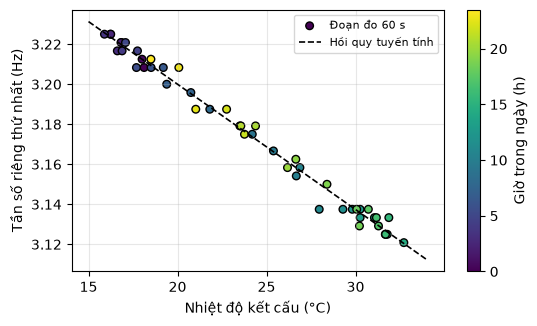

In [15]:
fig, ax = plt.subplots(figsize=(6.0, 3.4))
sc_ = ax.scatter(bang_dt["nhiet_do"], bang_dt["f1"],
                 c=bang_dt["gio"], cmap="viridis",
                 edgecolor="k", s=30, label="Đoạn đo 60 s")
T_ve = np.linspace(15, 34, 50)
ax.plot(T_ve, np.polyval(he_so, T_ve), "k--", lw=1.2,
        label="Hồi quy tuyến tính")
fig.colorbar(sc_, ax=ax, label="Giờ trong ngày (h)")
ax.set_xlabel("Nhiệt độ kết cấu (°C)")
ax.set_ylabel("Tần số riêng thứ nhất (Hz)")
ax.grid(alpha=0.3)
ax.legend(loc="upper right", fontsize=8)
plt.show()

## KẾT HỢP VÀ TỔNG HỢP DỮ LIỆU

### Kết hợp nhiều bảng dữ liệu

In [16]:
# Bang 1: thong tin cau kien
cau_kien = pd.DataFrame({
    "ma_ck": ["T1", "T2", "T3", "T4", "T5"],
    "hang_muc": ["Tru cau", "Tru cau", "Mo cau", "Tru cau",
                 "Mo cau"],
    "tram_tron": ["A", "B", "A", "B", "A"]})
# Bang 2: ket qua thi nghiem (MPa, cm), thieu ket qua T4
thi_nghiem = pd.DataFrame({
    "ma_ck": ["T1", "T2", "T3", "T5"],
    "cuong_do": [38.5, 35.2, 39.1, 37.4],
    "do_sut": [12, 14, 11, 13]})
tong_hop = cau_kien.merge(thi_nghiem, on="ma_ck", how="left",
                          indicator=True,
                          validate="one_to_one")
print(tong_hop.to_string(index=False))
chua_tn = tong_hop.loc[tong_hop["_merge"] == "left_only",
                       "ma_ck"].tolist()
print("Cau kien chua co ket qua thi nghiem:", chua_tn)

ma_ck hang_muc tram_tron  cuong_do  do_sut    _merge
   T1  Tru cau         A      38.5    12.0      both
   T2  Tru cau         B      35.2    14.0      both
   T3   Mo cau         A      39.1    11.0      both
   T4  Tru cau         B       NaN     NaN left_only
   T5   Mo cau         A      37.4    13.0      both
Cau kien chua co ket qua thi nghiem: ['T4']


### Tổng hợp dữ liệu theo nhóm

In [17]:
# Tong hop cuong do (MPa) theo tram tron
bao_cao = tong_hop.groupby("tram_tron")["cuong_do"].agg(
    so_mau="count", trung_binh="mean", do_lech_chuan="std",
    nho_nhat="min", lon_nhat="max").round(2)
print(bao_cao)
# Tong hop cheo theo hang muc va tram tron
bang_cheo = tong_hop.pivot_table(values="cuong_do",
                                 index="hang_muc",
                                 columns="tram_tron",
                                 aggfunc="mean")
print(bang_cheo.round(2))

           so_mau  trung_binh  do_lech_chuan  nho_nhat  lon_nhat
tram_tron                                                       
A               3       38.33           0.86      37.4      39.1
B               1       35.20            NaN      35.2      35.2
tram_tron      A     B
hang_muc              
Mo cau     38.25   NaN
Tru cau    38.50  35.2


In [18]:
# Quy doi chuoi theo gio sang khoang 6 gio
theo_6h = df[["do_vong_noi_suy", "nhiet_do"]].resample(
    "6h").agg(["mean", "max"])
print(theo_6h.round(2))

                    do_vong_noi_suy        nhiet_do      
                               mean    max     mean   max
thoi_diem                                                
2026-01-01 00:00:00           12.68  13.17    25.35  28.1
2026-01-01 06:00:00           12.97  13.50    25.48  28.4


### Ví dụ tổng hợp quy trình phân tích

In [19]:
# Buoc 4: hoi quy do vong theo nhiet do, chi dung so do that
sach = df.dropna(subset=["do_vong"])
hq = stats.linregress(sach["nhiet_do"], sach["do_vong"])
print("So diem dung de hoi quy:", len(sach))
print(f"r = {hq.rvalue:.3f}, R^2 = {hq.rvalue ** 2:.3f}")
print(f"He so goc = {hq.slope:.3f} mm/doC")
# Tuong quan khi doi do vong cham 1 gio so voi nhiet do
r_tre = df["nhiet_do"].corr(df["do_vong"].shift(-1))
print(f"r khi do vong tre 1 gio = {r_tre:.3f}")

So diem dung de hoi quy: 9
r = 0.921, R^2 = 0.848
He so goc = 0.189 mm/doC
r khi do vong tre 1 gio = 0.958


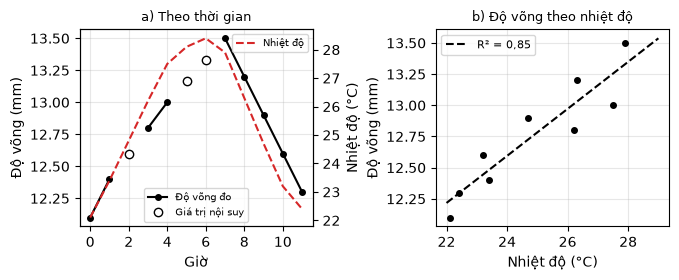

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.8, 2.9))
gio = df.index.hour
ax1.plot(gio, df["do_vong"], "ko-", ms=4, label="Độ võng đo")
thieu = df["do_vong"].isna()
ax1.plot(gio[thieu], df.loc[thieu, "do_vong_noi_suy"], "o",
         mfc="white", mec="k", ms=6, label="Giá trị nội suy")
ax1.set_xlabel("Giờ")
ax1.set_xticks(range(0, 12, 2))
ax1.set_ylabel("Độ võng (mm)")
ax1b = ax1.twinx()
ax1b.plot(gio, df["nhiet_do"], "--", color="C3",
          label="Nhiệt độ")
ax1b.set_ylabel("Nhiệt độ (°C)")
ax1b.legend(loc="upper right", fontsize=7)
ax1.set_title("a) Theo thời gian", fontsize=9)
ax1.legend(loc="lower center", fontsize=7)
ax1.grid(alpha=0.3)
ax2.plot(sach["nhiet_do"], sach["do_vong"], "ko", ms=4)
T_ve = np.linspace(22, 29, 20)
ax2.plot(T_ve, hq.intercept + hq.slope * T_ve, "k--",
         label=f"R² = {hq.rvalue ** 2:.2f}".replace(".", ","))
ax2.set_xlabel("Nhiệt độ (°C)")
ax2.set_ylabel("Độ võng (mm)")
ax2.set_title("b) Độ võng theo nhiệt độ", fontsize=9)
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## VÍ DỤ MINH HỌA VÀ BÀI TẬP

In [21]:
# Tep do luc cang day vang (gia dinh), dau phay thap phan
van_ban = '''vi_tri;mat_phang;luc_tk_kN;luc_do;don_vi
S1;TL;1850;1872;kN
S1;HL;1850;1838;kN
S2;TL;2120;2085;kN
S2;HL;2120;214,6;T
S3;TL;2480;2531;kN
S3;TL;2480;2531;kN
S3;HL;2480;2502;kN
S4;TL;2760;2915;kN
S4;HL;2760;2748;kN
S5;TL;3150;318,2;T
S5;HL;3150;;kN
S6;TL;3420;3395;kN
S6;HL;3420;3214;kN
'''
dc = pd.read_csv(io.StringIO(van_ban), sep=";", decimal=",")
n_doc = len(dc)
dc = dc.drop_duplicates().reset_index(drop=True)
print(f"Doc {n_doc} dong, sau khi bo trung con {len(dc)} dong")
la_tan = dc["don_vi"] == "T"
dc["luc_kN"] = dc["luc_do"].where(~la_tan, dc["luc_do"] * 9.81)
dc["sai_lech"] = (100 * (dc["luc_kN"] - dc["luc_tk_kN"])
                  / dc["luc_tk_kN"])                  # %
print(dc[["vi_tri", "mat_phang", "luc_tk_kN", "luc_kN",
          "sai_lech"]].round(1).to_string(index=False))

Doc 13 dong, sau khi bo trung con 12 dong
vi_tri mat_phang  luc_tk_kN  luc_kN  sai_lech
    S1        TL       1850  1872.0       1.2
    S1        HL       1850  1838.0      -0.6
    S2        TL       2120  2085.0      -1.7
    S2        HL       2120  2105.2      -0.7
    S3        TL       2480  2531.0       2.1
    S3        HL       2480  2502.0       0.9
    S4        TL       2760  2915.0       5.6
    S4        HL       2760  2748.0      -0.4
    S5        TL       3150  3121.5      -0.9
    S5        HL       3150     NaN       NaN
    S6        TL       3420  3395.0      -0.7
    S6        HL       3420  3214.0      -6.0


In [22]:
dc["ma"] = dc["vi_tri"] + "-" + dc["mat_phang"]
print("Thieu so lieu:",
      dc.loc[dc["luc_kN"].isna(), "ma"].tolist())
print("Sai lech > 5%:",
      dc.loc[dc["sai_lech"].abs() > 5, "ma"].tolist())
# Bang theo vi tri x mat phang, chenh lech cap doi xung
bang_dc = dc.pivot(index="vi_tri", columns="mat_phang",
                   values="luc_kN")[["TL", "HL"]]
tb_cap = (bang_dc["TL"] + bang_dc["HL"]) / 2
bang_dc["delta"] = (100 * (bang_dc["TL"] - bang_dc["HL"])
                    / tb_cap)                     # %
print(bang_dc.round(1))
lech = bang_dc.index[bang_dc["delta"].abs() > 5].tolist()
print("Cap doi xung |delta| > 5%:", lech)

Thieu so lieu: ['S5-HL']
Sai lech > 5%: ['S4-TL', 'S6-HL']
mat_phang      TL      HL  delta
vi_tri                          
S1         1872.0  1838.0    1.8
S2         2085.0  2105.2   -1.0
S3         2531.0  2502.0    1.2
S4         2915.0  2748.0    5.9
S5         3121.5     NaN    NaN
S6         3395.0  3214.0    5.5
Cap doi xung |delta| > 5%: ['S4', 'S6']


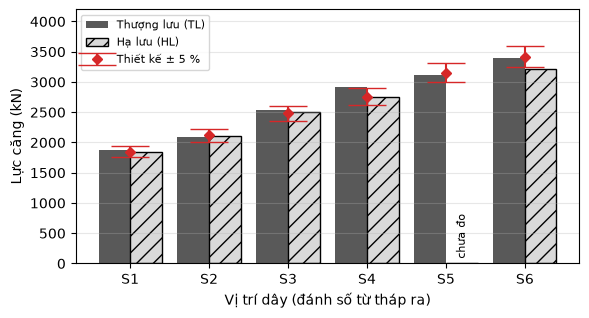

In [23]:
tk = dc.groupby("vi_tri")["luc_tk_kN"].first()
vt = np.arange(len(bang_dc))
fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.bar(vt - 0.2, bang_dc["TL"], 0.4, color="0.35",
       label="Thượng lưu (TL)")
ax.bar(vt + 0.2, bang_dc["HL"].fillna(0), 0.4, color="0.85",
       edgecolor="k", hatch="//", label="Hạ lưu (HL)")
ax.errorbar(vt, tk, yerr=0.05 * tk, fmt="D", color="C3",
            ms=5, capsize=14, label="Thiết kế ± 5 %")
ax.text(4.2, 80, "chưa đo", rotation=90, ha="center",
        va="bottom", fontsize=8)
ax.set_xticks(vt, bang_dc.index)
ax.set_xlabel("Vị trí dây (đánh số từ tháp ra)")
ax.set_ylabel("Lực căng (kN)")
ax.set_ylim(0, 4200)
ax.grid(alpha=0.3, axis="y")
ax.legend(loc="upper left", fontsize=8)
plt.show()

In [24]:
# Gia toc do MO PHONG A va B (khong phai ban ghi thuc)
fs_d = 100.0                      # Hz
dt = 1 / fs_d
t_d = np.arange(0, 30, dt)        # s

def gia_toc_do(hat, f1, f2, pga_g, t_dinh):
    # Nhieu trang loc thong dai f1-f2 (Hz) nhan ham bao
    rng = np.random.default_rng(hat)
    sos = signal.butter(4, [f1, f2], "bandpass", fs=fs_d,
                        output="sos")
    x = signal.sosfiltfilt(sos, rng.normal(0, 1, t_d.size))
    bao = (t_d / t_dinh) ** 2 * np.exp(2 * (1 - t_d / t_dinh))
    x = x * bao
    return pga_g * 9.81 * x / np.abs(x).max()     # m/s2

ag_A = gia_toc_do(7, 1.0, 8.0, 0.30, 3.0)
ag_B = gia_toc_do(23, 0.5, 1.5, 0.15, 5.0)
for ten, ag in (("A", ag_A), ("B", ag_B)):
    fw, P = signal.welch(ag, fs=fs_d, nperseg=1024)
    f_tr = fw[P.argmax()]
    print(f"{ten}: PGA = {np.abs(ag).max() / 9.81:.2f} g,"
          f" f troi = {f_tr:.2f} Hz, 1/f = {1 / f_tr:.2f} s")

A: PGA = 0.30 g, f troi = 2.73 Hz, 1/f = 0.37 s


B: PGA = 0.15 g, f troi = 0.68 Hz, 1/f = 1.46 s


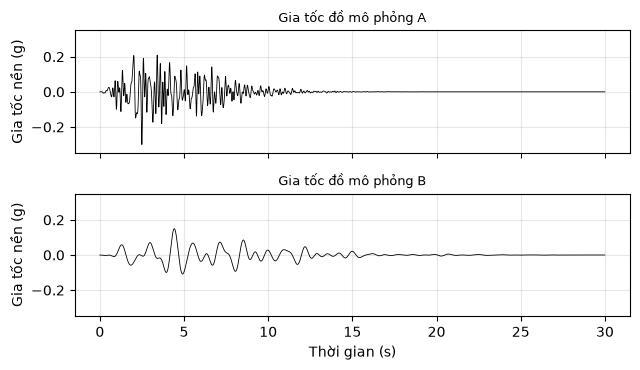

In [25]:
fig, axs = plt.subplots(2, 1, figsize=(6.5, 3.8),
                        sharex=True)
for ax, ag, ten in zip(axs, (ag_A, ag_B), ("A", "B")):
    ax.plot(t_d, ag / 9.81, color="k", lw=0.6)
    ax.set_ylabel("Gia tốc nền (g)")
    ax.set_title(f"Gia tốc đồ mô phỏng {ten}", fontsize=9)
    ax.set_ylim(-0.35, 0.35)
    ax.grid(alpha=0.3)
axs[1].set_xlabel("Thời gian (s)")
fig.tight_layout()
plt.show()

In [26]:
def pho_phan_ung(ag, T, xi=0.05):
    # S_d (m) cua ho he 1 BTD, Newmark gia toc trung binh
    wn = 2 * np.pi / T
    k, c = wn ** 2, 2 * xi * wn      # tren don vi khoi luong
    k_hd = k + 2 * c / dt + 4 / dt ** 2
    u = np.zeros_like(T)
    v = np.zeros_like(T)
    a = -ag[0] * np.ones_like(T)
    u_max = np.zeros_like(T)
    for p in -ag[1:]:
        p_hd = (p + (4 / dt ** 2 + 2 * c / dt) * u
                + (4 / dt + c) * v + a)
        du = p_hd / k_hd - u
        a = 4 * du / dt ** 2 - 4 * v / dt - a
        v = 2 * du / dt - v
        u = u + du
        u_max = np.maximum(u_max, np.abs(u))
    return u_max

T = np.round(np.arange(0.05, 4.001, 0.05), 2)
pho = pd.DataFrame({"T_s": T})
for ten, ag in (("A", ag_A), ("B", ag_B)):
    Sd = pho_phan_ung(ag, T)
    pho["Sd_" + ten] = 1000 * Sd                        # mm
    pho["PSa_" + ten] = (2 * np.pi / T) ** 2 * Sd / 9.81  # g
    i = pho["PSa_" + ten].idxmax()
    print(f"{ten}: PSa max = {pho.loc[i, 'PSa_' + ten]:.3f} g"
          f" tai T = {T[i]:.2f} s; Sd max ="
          f" {pho['Sd_' + ten].max():.1f} mm")
# Kiem tra bang scipy.signal.lsim tai T = 1 s
wn = 2 * np.pi / 1.0
he = signal.lti([-1], [1, 2 * 0.05 * wn, wn ** 2])
_, u_ls, _ = signal.lsim(he, ag_A, t_d)
sd1 = pho.loc[pho["T_s"] == 1.0, "Sd_A"].iloc[0]
print(f"T = 1 s, A: Newmark {sd1:.2f} mm,"
      f" lsim {1000 * np.abs(u_ls).max():.2f} mm")

A: PSa max = 0.789 g tai T = 0.20 s; Sd max = 42.5 mm
B: PSa max = 0.487 g tai T = 1.05 s; Sd max = 230.4 mm
T = 1 s, A: Newmark 34.61 mm, lsim 34.66 mm


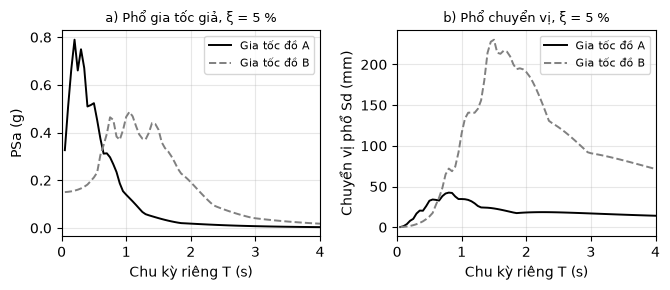

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.8, 3.0))
kieu = {"A": dict(color="k", ls="-"),
        "B": dict(color="0.5", ls="--")}
for ten in ("A", "B"):
    nhan = f"Gia tốc đồ {ten}"
    ax1.plot(T, pho["PSa_" + ten], lw=1.4, label=nhan,
             **kieu[ten])
    ax2.plot(T, pho["Sd_" + ten], lw=1.4, label=nhan,
             **kieu[ten])
ax1.set_ylabel("PSa (g)")
ax2.set_ylabel("Chuyển vị phổ Sd (mm)")
ax1.set_title("a) Phổ gia tốc giả, ξ = 5 %", fontsize=9)
ax2.set_title("b) Phổ chuyển vị, ξ = 5 %", fontsize=9)
for ax in (ax1, ax2):
    ax.set_xlabel("Chu kỳ riêng T (s)")
    ax.set_xlim(0, 4)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()